# PS4: LSTM for character-level text generation
Corpus: Shakespeare text, downloaded automatically.

In [1]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    print("=" * 62)
    print("GPU NOT FOUND - this notebook needs a GPU to train the LSTM.")
    print("How to fix:")
    print("  Colab : Runtime > Change runtime type > T4 GPU, then Run all.")
    print("  Local : install a CUDA-enabled TensorFlow build and retry.")
    print("=" * 62)
    raise SystemExit("Stopped: no GPU available.")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("Using GPU:", gpus[0].name)

Using GPU: /physical_device:GPU:0


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40
MAX_CHARS = 200000
keras.utils.set_random_seed(42)

In [3]:
path = keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt",
)
text = open(path, encoding="utf-8").read().lower()[:MAX_CHARS]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
id_to_char = np.array(chars)
print("Characters:", len(text), "Vocabulary:", len(chars))
print(text[:300])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Characters: 200000 Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [4]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, "y:", y.shape)

X: (66654, 40) y: (66654,)


In [5]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.LSTM(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       328,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 340,581 (1.30 MB)

 Trainable params: 340,581 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(X, y, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15
469/469 - 11s - 22ms/step - accuracy: 0.2737 - loss: 2.5635 - val_accuracy: 0.3404 - val_loss: 2.2627
Epoch 2/15
469/469 - 4s - 9ms/step - accuracy: 0.3899 - loss: 2.0741 - val_accuracy: 0.3983 - val_loss: 2.0616
Epoch 3/15
469/469 - 5s - 10ms/step - accuracy: 0.4433 - loss: 1.8760 - val_accuracy: 0.4266 - val_loss: 1.9504
Epoch 4/15
469/469 - 4s - 9ms/step - accuracy: 0.4812 - loss: 1.7334 - val_accuracy: 0.4505 - val_loss: 1.8716
Epoch 5/15
469/469 - 4s - 9ms/step - accuracy: 0.5104 - loss: 1.6228 - val_accuracy: 0.4652 - val_loss: 1.8286
Epoch 6/15
469/469 - 5s - 10ms/step - accuracy: 0.5329 - loss: 1.5354 - val_accuracy: 0.4716 - val_loss: 1.8123
Epoch 7/15
469/469 - 4s - 9ms/step - accuracy: 0.5555 - loss: 1.4575 - val_accuracy: 0.4769 - val_loss: 1.8108
Epoch 8/15
469/469 - 4s - 9ms/step - accuracy: 0.5753 - loss: 1.3830 - val_accuracy: 0.4797 - val_loss: 1.8201
Epoch 9/15
469/469 - 5s - 10ms/step - accuracy: 0.5974 - loss: 1.3095 - val_accuracy: 0.4767 - val_loss: 1.8

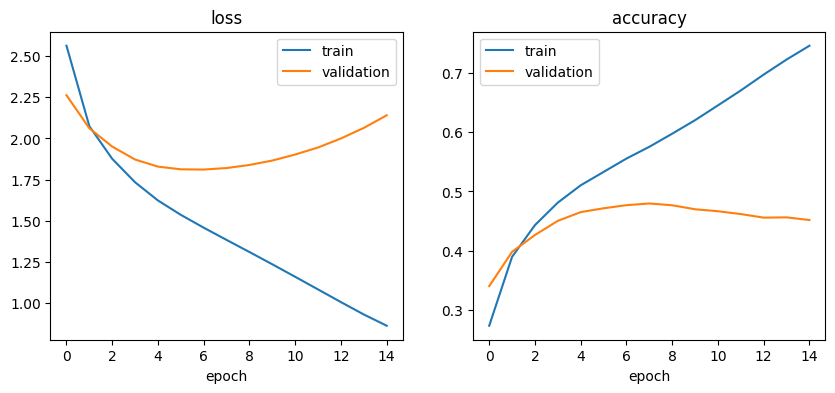

Final validation accuracy: 0.4518
Validation perplexity: 8.51


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [8]:
def generate(seed, n_chars=400, temperature=1.0):
    sentence = seed.lower()
    for _ in range(n_chars):
        context = sentence[-SEQ_LEN:]
        x = np.array([[char_to_id[c] for c in context]])
        probs = model.predict(x, verbose=0)[0]
        logits = np.log(probs + 1e-8) / temperature
        probs = np.exp(logits) / np.exp(logits).sum()
        sentence += id_to_char[np.random.choice(len(chars), p=probs)]
    return sentence

seed = "second citizen:\n"
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---
second citizen:
you have not confented me their less being
the noble more menenius and the did ner it.

menenius:
as as i could then:
the gods be gonger'd when servape their leave
he have not the people, and then tribe of rome
his never my bet'e the common's earn thence,
we have not conselfies than then, they have
and prefurer up, and truse me not the lide to them.

gloucester:
they done to him.

menenius:
well, 

--- temperature 0.5 ---
second citizen:
he thinds bet the mert me stilf fallowe,
you surve misseeble soldiel think, and theret'll treselves,
who, through i heard the people-'d the vilust
his not cears, ne so it shall refore than i have
no dellies how did sent for them, but shall be conseld
before the minger son here. he have not less him in chooled mence;
and fiver my to the give things, when, comel, come,
i have not plock him he hath r

--- temperature 1.0 ---
second citizen:
you have duscise meet he well conquess o' the cursen
we are recelfed up, i d